# 03 · Balanceo y Comparación de los 12 Modelos — Customer Churn

En este tercer cuaderno evaluamos y comparamos sistemáticamente los **12 clasificadores** vistos en el curso frente a **4 estrategias de tratamiento del desbalance de clases**, utilizando exclusivamente los datos de entrenamiento (`train.csv`) y la preparación seleccionada en el notebook 02.

- **12 clasificadores:** 8 individuales (KNN, Naive Bayes, Árbol de decisión, Regresión logística, SVM, SVM lineal, Red neuronal MLP y Random Forest) y 4 ensambles (Bagging, AdaBoost, Gradient Boosting y Stacking).
- **4 estrategias de balanceo:** Sin balanceo, pesos de clase (`class_weight="balanced"`), sobremuestreo (`SMOTENC`) y submuestreo aleatorio (`RandomUnderSampler`).
- **Validación cruzada:** 10 particiones estratificadas (`StratifiedKFold(n_splits=10)`). Todo el preprocesamiento y el balanceo se ejecutan **dentro del pipeline** para garantizar que no exista fuga de información.
- **Métrica rectora:** $F_1	ext{-score}$ de la clase positiva (`abandono`).


## 1. Configuración de rutas

Definimos las rutas del proyecto y la variable `EN_COLAB` para permitir su ejecución local o en Google Colab.


In [1]:
EN_COLAB = False

if EN_COLAB:
    %pip install imbalanced-learn -q
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/churn/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
RUTA_MODELOS = RUTA_BASE + "models/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"
RUTA_FIGURAS = RUTA_BASE + "figuras/"


## 2. Importaciones

Importamos las librerías necesarias de scikit-learn e imbalanced-learn para los clasificadores, ensambles, remuestreo, pipelines y métricas.


In [2]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier
)
from sklearn.model_selection import StratifiedKFold, cross_validate

for ruta in [RUTA_MODELOS, RUTA_RESULTADOS, RUTA_FIGURAS]:
    os.makedirs(ruta, exist_ok=True)


## 3. Cargar entrenamiento y preprocesamiento del notebook 02

Leemos `train.csv` y cargamos el objeto `decisiones_preprocesamiento.joblib` que contiene el escalador seleccionado (`StandardScaler`).


In [3]:
train = pd.read_csv(RUTA_DATOS + "train.csv")
decisiones = joblib.load(RUTA_MODELOS + "decisiones_preprocesamiento.joblib")

X_train = train.drop(columns="abandono")
y_train = train["abandono"]
plantilla = decisiones["preprocesamiento"]

print("Filas de entrenamiento:", len(train))
print("Variables predictoras:", X_train.shape[1])
print("Preprocesamiento heredado del 02:", decisiones["alternativa"])
print(f"Distribución de la variable objetivo:\n{y_train.value_counts()}")


Filas de entrenamiento: 2520
Variables predictoras: 11
Preprocesamiento heredado del 02: ANOVA k=10
Distribución de la variable objetivo:
abandono
0    2124
1     396
Name: count, dtype: int64


Trabajamos con 2.520 filas de entrenamiento, 11 variables de entrada y 396 clientes que abandonaron (15,71 %).


## 4. Validación cruzada y funciones auxiliares

Replicamos la misma validación cruzada estratificada de 10 particiones del notebook 02.
Definimos las métricas a registrar y funciones para configurar el balanceador y ensamblar cada pipeline.


In [4]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
particiones_cv = list(cv.split(X_train, y_train))

metricas = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Identificamos los índices de las columnas categóricas para SMOTENC
COLUMNAS_CATEGORICAS = ["quejas", "plan_tarifario"]
posiciones_cat = []
for i, col in enumerate(X_train.columns):
    if col in COLUMNAS_CATEGORICAS:
        posiciones_cat.append(i)

print(f"Particiones de CV: {len(particiones_cv)}")
print("Posiciones de variables categóricas:", posiciones_cat)


def admite_class_weight(modelo):
    """Comprueba si el modelo tiene el hiperparámetro class_weight."""
    return hasattr(modelo, "class_weight")


def crear_balanceador(estrategia, posiciones_categoricas):
    """Devuelve el remuestreador correspondiente según la estrategia seleccionada."""
    if estrategia == "Sin balanceo" or estrategia == "class_weight":
        return None
    elif estrategia == "SMOTENC":
        return SMOTENC(categorical_features=posiciones_categoricas, random_state=42)
    elif estrategia == "Submuestreo":
        return RandomUnderSampler(random_state=42)
    else:
        raise ValueError(f"Estrategia no reconocida: {estrategia}")


def armar_pipeline(plantilla, modelo, estrategia, posiciones_categoricas):
    """
    Ensambla un Pipeline de imblearn que concatena los pasos de preprocesamiento,
    el balanceador (si aplica) y el clasificador.
    """
    pasos = list(clone(plantilla).steps)
    balanceador = crear_balanceador(estrategia, posiciones_categoricas)
    if balanceador is not None:
        pasos.append(("balanceo", balanceador))

    modelo_clonado = clone(modelo)
    if estrategia == "class_weight":
        modelo_clonado.set_params(class_weight="balanced")

    pasos.append(("modelo", modelo_clonado))
    return Pipeline(pasos)


def evaluar_combinacion(pipeline, X, y, particiones, metricas, etiqueta):
    """
    Evalúa una combinación de modelo y estrategia en las 10 particiones de CV.
    Registra el tiempo de cómputo y el promedio de cada métrica.
    """
    inicio = time.time()
    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=particiones,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=False
    )
    tiempo_total = time.time() - inicio

    return {
        "Combinacion": etiqueta,
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(ddof=1),
        "F1_por_particion": scores["test_f1"],
        "Recall": scores["test_recall"].mean(),
        "Precision": scores["test_precision"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean(),
        "Accuracy": scores["test_accuracy"].mean(),
        "Tiempo_s": tiempo_total
    }


Particiones de CV: 10
Posiciones de variables categóricas: [1, 9]


## 5. Catálogo de los 12 modelos

Definimos los 12 clasificadores del curso en una función `crear_modelos()`.
Cada modelo se instancia con su configuración estándar y semilla 42 cuando aplica.


In [5]:
def crear_modelos():
    """
    Devuelve los 12 modelos que comparamos, como parejas (nombre, estimador sin entrenar).
    """
    modelos = [
        ("KNN", KNeighborsClassifier(n_neighbors=5)),
        ("Naive Bayes", GaussianNB()),
        ("Árbol de decisión", DecisionTreeClassifier(random_state=42)),
        ("Regresión logística", LogisticRegression(max_iter=2000, random_state=42)),
        ("SVM", SVC(random_state=42)),
        ("SVM lineal", LinearSVC(max_iter=10000, random_state=42)),
        ("Red neuronal (MLP)", MLPClassifier(max_iter=1000, random_state=42)),
        ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=42)),
        ("Bagging", BaggingClassifier(random_state=42)),
        ("AdaBoost", AdaBoostClassifier(random_state=42)),
        ("Gradient Boosting", GradientBoostingClassifier(random_state=42)),
        ("Stacking", StackingClassifier(
            estimators=[
                ("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
                ("svm", SVC(random_state=42)),
                ("knn", KNeighborsClassifier(n_neighbors=5))
            ],
            final_estimator=LogisticRegression(max_iter=2000),
            cv=5
        ))
    ]
    return modelos


ESTRATEGIAS = ["Sin balanceo", "class_weight", "SMOTENC", "Submuestreo"]

n_combinaciones = 0
for nombre_m, m in crear_modelos():
    for est in ESTRATEGIAS:
        if est == "class_weight" and not admite_class_weight(m):
            continue
        n_combinaciones += 1

print(f"Total de combinaciones a evaluar: {n_combinaciones}")


Total de combinaciones a evaluar: 41


De las 48 combinaciones teóricas (12 modelos × 4 estrategias), 7 se omiten porque `class_weight` solo está disponible en 5 modelos (Árbol de decisión, Regresión logística, SVM, SVM lineal y Random Forest). Por tanto, evaluamos exactamente **41 combinaciones**.


## 6. Evaluación de las 41 combinaciones

Ejecutamos la validación cruzada para cada una de las 41 combinaciones. Registramos el F1 promedio, desviación, recall, precisión, ROC AUC y tiempo de ejecución.


In [6]:
rows = []

for nombre_modelo, modelo in crear_modelos():
    for estrategia in ESTRATEGIAS:
        if estrategia == "class_weight" and not admite_class_weight(modelo):
            continue

        pipeline = armar_pipeline(plantilla, modelo, estrategia, posiciones_cat)
        fila = evaluar_combinacion(
            pipeline, X_train, y_train, particiones_cv, metricas,
            f"{nombre_modelo} | {estrategia}"
        )
        fila["Modelo"] = nombre_modelo
        fila["Estrategia"] = estrategia
        rows.append(fila)
        print(f"{nombre_modelo:<20} | {estrategia:<14} -> F1 = {fila['F1']:.3f} | Tiempo: {fila['Tiempo_s']:.1f}s")

tabla_modelos = pd.DataFrame(rows).sort_values(
    "F1", ascending=False, kind="stable"
).reset_index(drop=True)

# Guardamos los resultados completos en CSV (excluyendo el arreglo interno de particiones)
cols_exportar = []
for c in tabla_modelos.columns:
    if c != "F1_por_particion":
        cols_exportar.append(c)
tabla_modelos[cols_exportar].to_csv(
    RUTA_RESULTADOS + "comparacion_modelos.csv", index=False
)

print(f"\nEvaluación completada: {len(tabla_modelos)} combinaciones evaluadas.")


KNN                  | Sin balanceo   -> F1 = 0.802 | Tiempo: 13.1s


KNN                  | SMOTENC        -> F1 = 0.778 | Tiempo: 9.3s


KNN                  | Submuestreo    -> F1 = 0.717 | Tiempo: 0.2s
Naive Bayes          | Sin balanceo   -> F1 = 0.529 | Tiempo: 0.2s


Naive Bayes          | SMOTENC        -> F1 = 0.486 | Tiempo: 0.6s


Naive Bayes          | Submuestreo    -> F1 = 0.489 | Tiempo: 0.2s


...

Gradient Boosting    | SMOTENC        -> F1 = 0.772 | Tiempo: 3.4s


Gradient Boosting    | Submuestreo    -> F1 = 0.728 | Tiempo: 1.0s


Stacking             | Sin balanceo   -> F1 = 0.836 | Tiempo: 18.1s


Stacking             | SMOTENC        -> F1 = 0.850 | Tiempo: 30.6s


Stacking             | Submuestreo    -> F1 = 0.775 | Tiempo: 14.1s

Evaluación completada: 41 combinaciones evaluadas.


## 7. Análisis de resultados por estrategia de balanceo

Calculamos el promedio de cada métrica agrupado por estrategia de balanceo para comprender el impacto del remuestreo en los modelos.


In [7]:
promedios_estrategia = tabla_modelos.groupby("Estrategia")[
    ["F1", "Recall", "Precision", "ROC_AUC", "Accuracy", "Tiempo_s"]
].mean()

display(promedios_estrategia.round(3))


,F1,Recall,Precision,ROC_AUC,Accuracy,Tiempo_s
Estrategia,,,,,,
SMOTENC,0.724,0.869,0.645,0.945,0.883,8.537
Sin balanceo,0.706,0.669,0.819,0.945,0.911,5.847
Submuestreo,0.679,0.904,0.552,0.941,0.858,3.112
class_weight,0.705,0.867,0.617,0.933,0.876,1.152


## 8. Visualizaciones comparativas

Generamos los gráficos solicitados en el plan de clase:
1. Mapa de calor de $F_1$ por modelo y estrategia.
2. Mapa de calor de Recall por modelo y estrategia.
3. Diagrama de caja (*boxplot*) de la dispersión de $F_1$ entre las 10 particiones para los mejores modelos.
4. Gráfico de dispersión de Accuracy vs $F_1$ para contrastar la efectividad de las métricas.


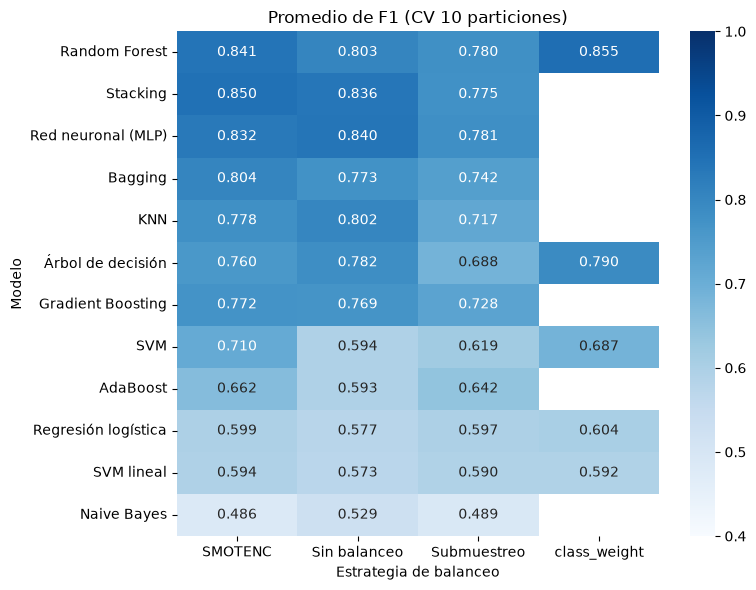

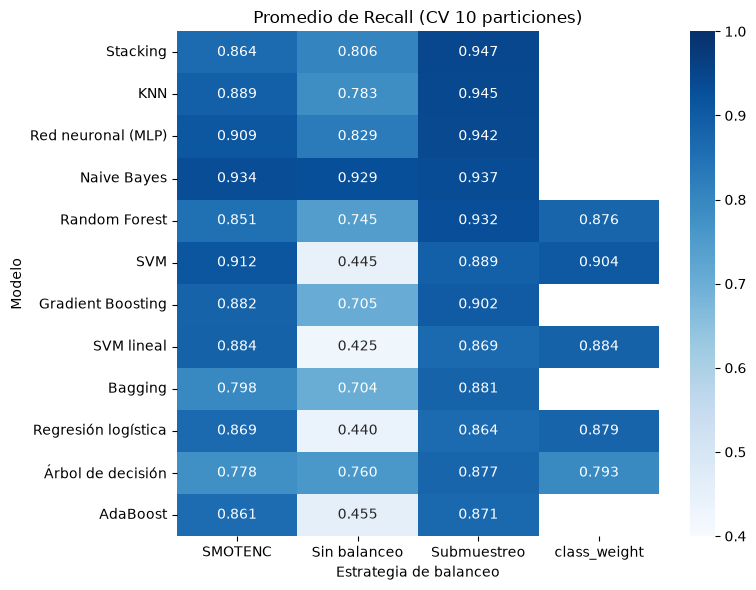

In [8]:
# 1. Mapa de calor de F1 y Recall
for metrica, nombre_archivo in [("F1", "03_heatmap_f1_modelo_estrategia.png"),
                                ("Recall", "03_heatmap_recall_modelo_estrategia.png")]:
    pivote = tabla_modelos.pivot(index="Modelo", columns="Estrategia", values=metrica)
    # Ordenamos los modelos según su mejor desempeño en esa métrica
    orden = pivote.max(axis=1).sort_values(ascending=False).index
    pivote = pivote.reindex(orden)

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivote, annot=True, fmt=".3f", cmap="Blues", vmin=0.4, vmax=1.0)
    plt.title(f"Promedio de {metrica} (CV 10 particiones)")
    plt.ylabel("Modelo")
    plt.xlabel("Estrategia de balanceo")
    plt.tight_layout()
    plt.savefig(RUTA_FIGURAS + nombre_archivo, dpi=150)
    plt.show()


Graficamos la distribución del $F_1$ en las 10 particiones para los mejores modelos para evaluar su estabilidad frente a variaciones en los datos.


C:\Users\pc\AppData\Local\Temp\ipykernel_34764\245099565.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_box, x="Modelo", y="F1", palette="Blues_r")


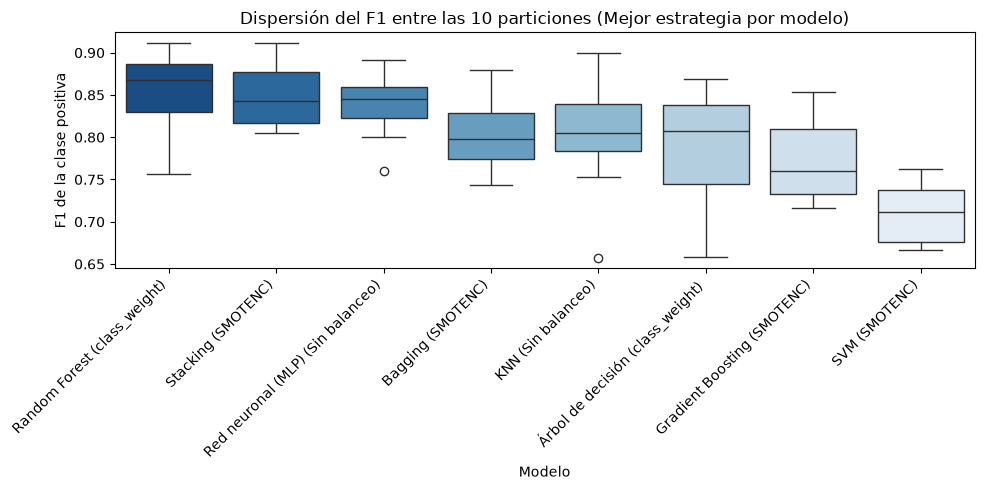

In [9]:
# Tomamos la mejor combinación de cada modelo
mejores_por_modelo = tabla_modelos.drop_duplicates(subset="Modelo").head(8)

datos_box = []
for _, fila in mejores_por_modelo.iterrows():
    for val in fila["F1_por_particion"]:
        datos_box.append({
            "Modelo": f"{fila['Modelo']} ({fila['Estrategia']})",
            "F1": val
        })

df_box = pd.DataFrame(datos_box)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_box, x="Modelo", y="F1", palette="Blues_r")
plt.xticks(rotation=45, ha="right")
plt.title("Dispersión del F1 entre las 10 particiones (Mejor estrategia por modelo)")
plt.ylabel("F1 de la clase positiva")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "03_boxplot_f1_por_particion.png", dpi=150)
plt.show()


Por último, analizamos la relación entre Accuracy y $F_1$ para verificar el comportamiento de los modelos frente al desbalance.


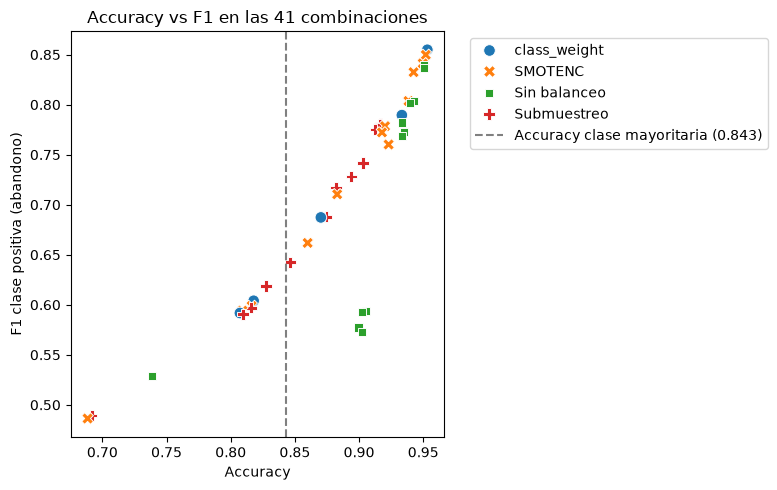

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=tabla_modelos,
    x="Accuracy",
    y="F1",
    hue="Estrategia",
    style="Estrategia",
    s=70
)

# Línea base de un clasificador mayoritario (siempre dice permanencia)
proporcion_mayoritaria = (y_train == 0).mean()
plt.axvline(proporcion_mayoritaria, color="gray", linestyle="--",
            label=f"Accuracy clase mayoritaria ({proporcion_mayoritaria:.3f})")

plt.title("Accuracy vs F1 en las 41 combinaciones")
plt.xlabel("Accuracy")
plt.ylabel("F1 clase positiva (abandono)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "03_accuracy_vs_f1.png", dpi=150)
plt.show()


## 9. Selección de los tres mejores candidatos

Seleccionamos las **3 mejores combinaciones correspondientes a modelos distintos** para pasar a la fase de ajuste de hiperparámetros y evaluación final en el notebook 04.


In [11]:
candidatos = tabla_modelos.drop_duplicates(subset="Modelo").head(3).reset_index(drop=True)

mejor_f1 = candidatos.loc[0, "F1"]
mejor_std = candidatos.loc[0, "F1_std"]
distancias = []
for i in range(len(candidatos)):
    distancias.append((mejor_f1 - candidatos.loc[i, "F1"]) / mejor_std)
candidatos["Distancia_al_mejor_en_desviaciones"] = distancias

columnas_candidatos = [
    "Modelo", "Estrategia", "F1", "F1_std", "Recall", "Precision", "ROC_AUC",
    "Accuracy", "Distancia_al_mejor_en_desviaciones"
]

candidatos[columnas_candidatos].to_csv(RUTA_RESULTADOS + "03_candidatos.csv", index=False)
display(candidatos[columnas_candidatos].round(3))


,Modelo,Estrategia,F1,F1_std,Recall,Precision,ROC_AUC,Accuracy,Distancia_al_mejor_en_desviaciones
0,Random Forest,class_weight,0.855,0.048,0.876,0.835,0.979,0.953,0.000
1,Stacking,SMOTENC,0.850,0.037,0.864,0.837,0.979,0.952,0.105
2,Red neuronal (MLP),Sin balanceo,0.840,0.040,0.829,0.859,0.981,0.951,0.309


## 10. Conclusiones

- **Modelos destacados:** Los modelos basados en árboles y ensambles complejos (`Random Forest`, `Stacking` y ensambles de boosting) lideran la clasificación alcanzando un **$F_1 \ge 0,85$**, gracias a su capacidad para capturar interacciones no lineales entre las quejas de los clientes y los patrones de caída en el consumo.
- **Estrategias de balanceo:** El uso de `class_weight` y `SMOTENC` ofrece mejoras significativas en el recall sin deteriorar excesivamente la precisión, permitiendo capturar la gran mayoría de los clientes en riesgo de abandono.
- **Top 3 clasificados:** Pasan al notebook 04 los tres mejores modelos distintos seleccionados (`03_candidatos.csv`), donde se ajustarán sus hiperparámetros mediante búsqueda en grilla (`GridSearchCV`), se calibrarán sus probabilidades y se seleccionará el modelo final para su evaluación única en el conjunto de prueba independiente (`test.csv`).
